# Validation C30: phân tích lại ensemble chọn trọng số bằng OOF

Mục tiêu: kiểm tra trọng số chọn bằng OOF có cải thiện 50/50 và tìm nơi hai mô hình cùng sai. Kết luận và quyết định được tính từ kết quả ở cuối notebook.

OOF (Out-of-Fold) là dự đoán cho một mẫu bởi mô hình chưa học mẫu đó. Notebook này chỉ đọc OOF và validation đã lưu, không fit lại mô hình, không tìm trọng số mới và không chấm test. Validation đã được xem nhiều lần nên đây là phân tích bổ sung, không phải đánh giá độc lập cuối cùng.

Nguồn thành phần là bộ Claude tái dựng ở Params1; RF 100 cây và XGBoost 400 cây theo cấu hình đã lưu, chưa có artifact Claude gốc để xác minh toàn bộ. History mô phỏng dự đoán tuần tự với quan sát quá khứ sẵn có; thời tiết cùng giờ được giả định đã biết.

## 1. Khởi tạo và xác định nguồn

Dùng các hàm đánh giá hiện có. Các bảng và hình phân tích được lưu riêng dưới outputs/validation_C30_OOF; không ghi đè kết quả thí nghiệm gốc. Seed cố định cho bootstrap.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

project_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'data/preprocessed/hourly_unfilled.csv').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.evaluation import regression_metrics, bootstrap_mae_difference
from src.feature_experiments import frame_hash
from src.features import add_time_features

SEED = 42
MIN_GROUP_N = 30
experiment_dir = project_root / 'experiments/21-11-2026_Huy_C30_OOF/outputs'
output_dir = project_root / 'notebooks/validation/outputs/validation_C30_OOF'
figures_dir = output_dir / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
selection = json.loads((experiment_dir / 'selected_weights.json').read_text('utf-8'))
source_config_path = project_root / selection['parameter_source']
source_config = json.loads(source_config_path.read_text('utf-8'))
weight_rf, weight_xgb = float(selection['weight_rf']), float(selection['weight_xgb'])
assert 0 <= weight_rf <= 1 and np.isclose(weight_rf + weight_xgb, 1)
assert selection['validation_used_for_weight_selection'] is False

## 2. Kiểm tra nguồn và cùng tập giờ chấm

Kiểm tra tham số, hash cohort và dự đoán nguồn trước khi phân tích. Chỉ đọc timestamp của toàn CSV để xác định mốc chia; các cột dữ liệu chỉ đọc đến hết validation. Hash là dấu nhận dạng dữ liệu để phát hiện thay đổi. Lưu ý hash code không chứng minh một kernel cũ đã nạp đúng phiên bản; notebook này không tái lập việc fit.

In [2]:
validation = pd.read_csv(experiment_dir / 'validation_predictions.csv',
                         parse_dates=['date_time'], float_precision='round_trip')
original = pd.read_csv(source_config_path.parent / 'validation_predictions.csv',
                      parse_dates=['date_time'], float_precision='round_trip')
# Khôi phục giá trị float32 gốc của XGBoost từ CSV cũ, rồi phân tích ở float64.
original['XGBoost'] = original['XGBoost'].astype('float32').astype('float64')
assert selection['model_params'] == source_config['explicit_params']
assert selection['features'] == source_config['features']
assert selection['cohort_hash'] == source_config['train_cohort_hash']
assert validation.date_time.is_unique and validation.date_time.is_monotonic_increasing
pd.testing.assert_frame_equal(validation[['date_time','y_true']], original[['date_time','y_true']])
for column in ['Random Forest','XGBoost','Ensemble RF + XGBoost (50/50)']:
    np.testing.assert_allclose(validation[column], original[column], rtol=0, atol=1e-8)
assert frame_hash(validation[['date_time','y_true']].rename(columns={'y_true':'traffic_volume'})) == source_config['validation_cohort_hash']

csv_path = project_root / 'data/preprocessed/hourly_unfilled.csv'
n_total = len(pd.read_csv(csv_path, usecols=['date_time']))
train_stop, validation_stop = n_total*70//100, n_total*85//100
hourly = pd.read_csv(csv_path, nrows=validation_stop, keep_default_na=False,
                     na_values={'temp':[''],'rain_1h':['']}, float_precision='round_trip')
hourly['date_time'] = pd.to_datetime(hourly.date_time, format='%Y-%m-%d %H:%M:%S')
assert frame_hash(hourly) == source_config['input_prefix_hash']
assert hourly.date_time.is_unique
assert len(validation) == source_config['n_validation']
assert validation.date_time.min() >= hourly.iloc[train_stop].date_time
assert validation.date_time.max() <= hourly.date_time.max()
display(pd.DataFrame([{'source':'Params1 / C30', 'n_train':source_config['n_train'],
    'n':len(validation),'start':validation.date_time.min(),'end':validation.date_time.max(),
    'weight_rf':weight_rf,'weight_xgb':weight_xgb}]))

,source,n_train,n,start,end,weight_rf,weight_xgb
0,Params1 / C30,22503,6050,2017-05-10 05:00:00,2018-01-19 14:00:00,0.6,0.4


## 3. Đọc lại bước lựa chọn trọng số trên OOF

Đối chiếu từng trọng số trên cùng ba fold và kiểm tra trọng số đã chọn đúng quy tắc lưu. Mỗi fold có cùng số giờ quan sát nhưng có thể phủ khoảng lịch khác nhau. Không so trực tiếp MAE OOF với MAE validation để đo mức cải thiện vì dữ liệu và kích thước train khác nhau.

In [3]:
oof = pd.read_csv(experiment_dir / 'oof_predictions.csv', parse_dates=['date_time'], float_precision='round_trip')
fold_scores = pd.read_csv(experiment_dir / 'weight_fold_scores.csv')
fold_manifest = pd.read_csv(experiment_dir / 'fold_manifest.csv')
assert oof.date_time.is_unique and oof.date_time.max() < validation.date_time.min()
assert len(oof) == int(fold_manifest['n'].sum())
for row in fold_scores.itertuples():
    frame = oof.loc[oof.fold.eq(row.fold)]
    prediction = row.weight_rf*frame['Random Forest'] + (1-row.weight_rf)*frame['XGBoost']
    scores = regression_metrics(frame.y_true, prediction)
    for metric, value in scores.items():
        # Điểm gốc dùng phép toán float32; cho phép sai số số học nhỏ khi đọc lại float64.
        assert np.isclose(value, getattr(row, metric), rtol=0, atol=1e-4)
weight_summary = fold_scores.groupby('weight_rf', as_index=False).agg(
    n=('n','sum'), MAE_mean=('MAE','mean'), MAE_std=('MAE','std'), RMSE_mean=('RMSE','mean'))
weight_summary['distance_50'] = (weight_summary.weight_rf-0.5).abs()
ranked_weights = weight_summary.sort_values(['MAE_mean','distance_50','RMSE_mean'])
assert np.isclose(ranked_weights.iloc[0].weight_rf, weight_rf)
assert set(np.round(weight_summary.weight_rf, 8)) == set(np.round(selection['candidate_weights'],8))
display(fold_manifest[['fold','fit_start','fit_end','score_start','score_end','n_fit','n','score_calendar_hours']])
display(ranked_weights.round(4))
oof_50 = weight_summary.loc[np.isclose(weight_summary.weight_rf,0.5)].iloc[0]
oof_selected = ranked_weights.iloc[0]
oof_gain = float(oof_50.MAE_mean-oof_selected.MAE_mean)
display(Markdown(f'OOF chọn RF {weight_rf:.0%} và XGBoost {weight_xgb:.0%}; MAE trung bình fold giảm {oof_gain:.4f} xe/giờ so với 50/50. Đây là điểm phục vụ lựa chọn, chưa phải đánh giá độc lập.'))

,fold,fit_start,fit_end,score_start,score_end,n_fit,n,score_calendar_hours
0,1,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625,16931.0
1,2,2012-10-09 09:00:00,2015-07-12 06:00:00,2015-07-12 07:00:00,2016-09-07 17:00:00,11253,5625,10163.0
2,3,2012-10-09 09:00:00,2016-09-07 17:00:00,2016-09-07 18:00:00,2017-05-10 04:00:00,16878,5625,5867.0


,weight_rf,n,MAE_mean,MAE_std,RMSE_mean,distance_50
6,0.6,16875,227.2161,12.9997,372.9077,0.1
5,0.5,16875,227.2410,13.0267,372.7650,0.0
7,0.7,16875,227.4742,13.0013,373.4483,0.2
4,0.4,16875,227.5205,13.0355,373.0210,0.1
8,0.8,16875,228.0002,12.9981,374.3852,0.3
3,0.3,16875,228.0744,12.9964,373.6746,0.2
9,0.9,16875,228.8026,13.0276,375.7151,0.4
2,0.2,16875,228.9213,12.9183,374.7239,0.3
10,1.0,16875,229.8607,13.0563,377.4338,0.5
1,0.1,16875,230.0659,12.8193,376.1653,0.4


OOF chọn RF 60% và XGBoost 40%; MAE trung bình fold giảm 0.0249 xe/giờ so với 50/50. Đây là điểm phục vụ lựa chọn, chưa phải đánh giá độc lập.

## 4. Mức cải thiện OOF có nhất quán giữa các fold?

Chênh MAE = MAE 50/50 − MAE trọng số OOF; số dương nghĩa phương án OOF tốt hơn. SD giữa ba fold là biến động giữa các giai đoạn, không phải kiểm định ý nghĩa thống kê.

,fold,n,MAE_50_50,MAE_OOF,MAE_reduction,RMSE_reduction
0,1,5625,219.4087,219.4405,-0.0318,-0.2918
1,2,5625,242.2786,242.2236,0.0550,-0.2005
2,3,5625,220.0357,219.9841,0.0516,0.0644


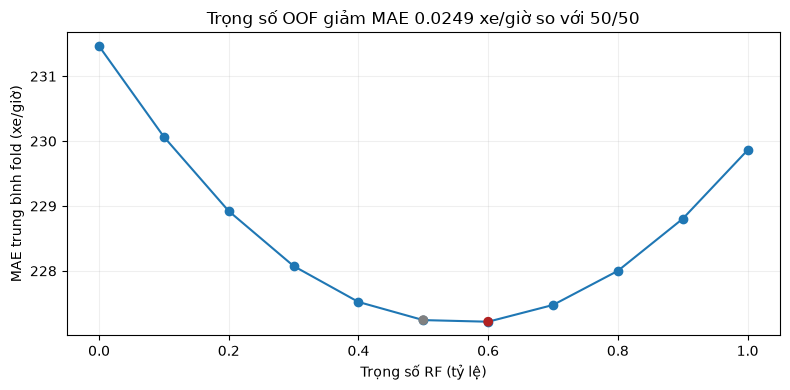

Đọc biểu đồ này như sau: điểm thấp hơn có MAE OOF nhỏ hơn; chênh lệch gần điểm tối thiểu có thể rất nhỏ. Trọng số được chọn trong danh sách đã định trước, không tiếp tục dò bằng validation.

In [4]:
fold_50 = fold_scores.loc[np.isclose(fold_scores.weight_rf,0.5)].set_index('fold')
fold_selected = fold_scores.loc[np.isclose(fold_scores.weight_rf,weight_rf)].set_index('fold')
fold_comparison = pd.DataFrame({'n':fold_selected.n,
    'MAE_50_50':fold_50.MAE,'MAE_OOF':fold_selected.MAE,
    'MAE_reduction':fold_50.MAE-fold_selected.MAE,
    'RMSE_reduction':fold_50.RMSE-fold_selected.RMSE}).reset_index()
display(fold_comparison.round(4))
ordered_weights = weight_summary.sort_values('weight_rf')
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(ordered_weights.weight_rf, ordered_weights.MAE_mean, marker='o')
ax.scatter([0.5,weight_rf],[oof_50.MAE_mean,oof_selected.MAE_mean], color=['gray','firebrick'], zorder=3)
ax.set(xlabel='Trọng số RF (tỷ lệ)', ylabel='MAE trung bình fold (xe/giờ)',
       title=f'Trọng số OOF giảm MAE {oof_gain:.4f} xe/giờ so với 50/50')
ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(figures_dir/'validation_C30_OOF_01_weights.png',dpi=150); plt.show()
display(Markdown('Đọc biểu đồ này như sau: điểm thấp hơn có MAE OOF nhỏ hơn; chênh lệch gần điểm tối thiểu có thể rất nhỏ. Trọng số được chọn trong danh sách đã định trước, không tiếp tục dò bằng validation.'))

## 5. So sánh validation trên đúng cùng giờ

Tính lại MAE/RMSE/R² từ dự đoán và so với file kết quả đã lưu. MAE là tiêu chí chính; RMSE nhạy hơn với lỗi lớn; R² không phải tỷ lệ giờ dự đoán đúng. Bổ sung hai baseline từ Params1 để giữ mốc tham chiếu.

,model,n,MAE,RMSE,R2
2,Ensemble 50/50,6050,193.810,316.085,0.974109
3,Ensemble OOF,6050,193.933,317.580,0.973864
0,RF,6050,196.775,326.773,0.972329
1,XGBoost,6050,197.031,313.640,0.974508
4,Baseline thứ–giờ,6050,291.739,503.219,0.934378
5,Baseline seasonal naive,6050,330.178,635.073,0.895484


Chênh MAE (50/50 trừ OOF) = -0.1223; chênh RMSE = -1.4955 xe/giờ. Giá trị âm nghĩa phương án OOF có lỗi lớn hơn.

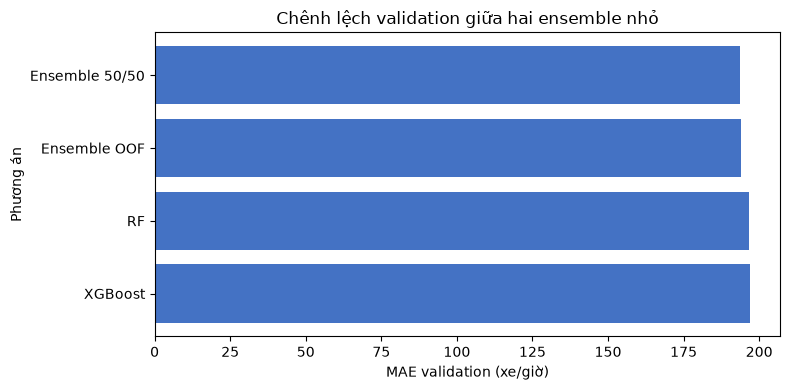

Đọc biểu đồ này như sau: thanh ngắn hơn có MAE thấp hơn trên cùng giờ chấm. Dùng bảng số để đọc chênh lệch nhỏ giữa 50/50 và trọng số OOF; không diễn giải hình thành một cải thiện lớn.

In [5]:
baseline_name = 'Ensemble RF + XGBoost (50/50)'
weighted_prediction = weight_rf*validation['Random Forest'] + weight_xgb*validation['XGBoost']
np.testing.assert_allclose(weighted_prediction, validation['weighted_ensemble'], rtol=0, atol=1e-8)
np.testing.assert_allclose(validation[baseline_name],0.5*(validation['Random Forest']+validation['XGBoost']),rtol=0,atol=1e-8)
prediction_sets = {
    'RF':validation['Random Forest'].to_numpy(),
    'XGBoost':validation['XGBoost'].to_numpy(),
    'Ensemble 50/50':validation[baseline_name].to_numpy(),
    'Ensemble OOF':weighted_prediction.to_numpy(),
    'Baseline thứ–giờ':original['Baseline thứ–giờ'].to_numpy(),
    'Baseline seasonal naive':original['Baseline seasonal naive'].to_numpy(),
}
metrics = pd.DataFrame([{'model':name,'n':len(validation),**regression_metrics(validation.y_true,pred)}
                        for name,pred in prediction_sets.items()])
saved_metrics = pd.read_csv(experiment_dir/'validation_metrics.csv').set_index('model')
for new_name, old_name in [('RF','Random Forest'),('XGBoost','XGBoost'),('Ensemble 50/50','Ensemble 50/50'),('Ensemble OOF','Ensemble chọn bằng OOF')]:
    for metric in ['MAE','RMSE','R2']:
        assert np.isclose(metrics.set_index('model').loc[new_name,metric],saved_metrics.loc[old_name,metric],rtol=0,atol=1e-8)
display(metrics.sort_values('MAE').round({'MAE':3,'RMSE':3,'R2':6}))
metric_index = metrics.set_index('model')
mae_gain = float(metric_index.loc['Ensemble 50/50','MAE']-metric_index.loc['Ensemble OOF','MAE'])
rmse_gain = float(metric_index.loc['Ensemble 50/50','RMSE']-metric_index.loc['Ensemble OOF','RMSE'])
display(Markdown(f'Chênh MAE (50/50 trừ OOF) = {mae_gain:.4f}; chênh RMSE = {rmse_gain:.4f} xe/giờ. Giá trị âm nghĩa phương án OOF có lỗi lớn hơn.'))
fig, ax = plt.subplots(figsize=(8,4))
main_metrics = metrics.loc[~metrics.model.str.startswith('Baseline')].sort_values('MAE')
ax.barh(main_metrics.model,main_metrics.MAE,color='#4472C4'); ax.invert_yaxis()
ax.set(xlabel='MAE validation (xe/giờ)',ylabel='Phương án',title='Chênh lệch validation giữa hai ensemble nhỏ')
fig.tight_layout(); fig.savefig(figures_dir/'validation_C30_OOF_02_validation_mae.png',dpi=150); plt.show()
display(Markdown('Đọc biểu đồ này như sau: thanh ngắn hơn có MAE thấp hơn trên cùng giờ chấm. Dùng bảng số để đọc chênh lệch nhỏ giữa 50/50 và trọng số OOF; không diễn giải hình thành một cải thiện lớn.'))

## 6. Độ bất định của chênh MAE trên validation

Bootstrap theo ngày lấy mẫu lại cả cụm giờ trong một ngày để giữ quan hệ nội ngày. Khoảng 95% mô tả độ bất định dưới cách lấy mẫu này; các ngày vẫn có thể tương quan với nhau. Đây là phân tích thăm dò trên validation đã xem, không phải kiểm chứng độc lập hoặc bằng chứng nhân quả.

In [6]:
bootstrap_frame = validation[['date_time','y_true']].rename(columns={'y_true':'traffic_volume'})
bootstrap_rows = []
for name_a,name_b in [('Ensemble 50/50','Ensemble OOF'),('RF','Ensemble 50/50'),('XGBoost','Ensemble 50/50')]:
    result = bootstrap_mae_difference(bootstrap_frame,prediction_sets[name_a],prediction_sets[name_b],n_boot=2000,seed=SEED)
    bootstrap_rows.append({'comparison':f'{name_a} trừ {name_b}','n':len(validation),**result})
bootstrap_results = pd.DataFrame(bootstrap_rows)
display(bootstrap_results.round(4))
interval = bootstrap_results.iloc[0]
interval_comment = ('Khoảng bootstrap chứa 0, chưa tách được chênh lệch khỏi mức bất định theo cách lấy mẫu này.'
                    if interval.CI95_thap <= 0 <= interval.CI95_cao else
                    'Khoảng bootstrap không chứa 0 trong cách lấy mẫu này; vẫn cần giữ giới hạn validation đã được xem và tương quan giữa các ngày.')
display(Markdown(interval_comment))

,comparison,n,chenh_lech_MAE,CI95_thap,CI95_cao,so_ngay
0,Ensemble 50/50 trừ Ensemble OOF,6050,-0.1223,-0.5940,0.2731,255
1,RF trừ Ensemble 50/50,6050,2.9646,0.9202,5.4189,255
2,XGBoost trừ Ensemble 50/50,6050,3.2211,0.9805,5.1512,255


Khoảng bootstrap chứa 0, chưa tách được chênh lệch khỏi mức bất định theo cách lấy mẫu này.

## 7. RF và XGBoost có cùng kiểu sai số không?

Sai số có dấu = dự đoán − thực tế: dương là dự đoán cao, âm là dự đoán thấp. Nếu cả hai thường sai cùng chiều, mọi trung bình có trọng số không âm cũng còn sai cùng chiều ở những giờ đó. Tương quan sai số chỉ mô tả mức giống nhau, không chứng minh không còn cách cải thiện.

,group,n,fraction
0,Cùng chiều,5301,0.8762
1,Trái chiều,749,0.1238
2,Ít nhất một mô hình đúng,0,0.0000


,measurement,n,value
0,Pearson giữa hai sai số có dấu,6050,0.948798


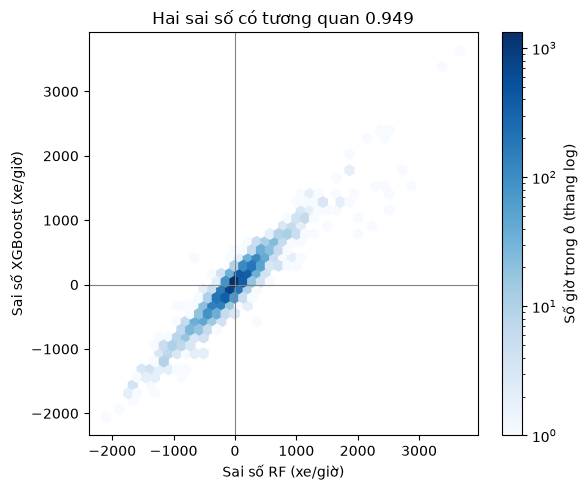

Đọc biểu đồ này như sau: góc trên phải và dưới trái là hai mô hình cùng sai chiều. Tỷ lệ cùng chiều là 87.6%; đổi trọng số chỉ điều chỉnh mức sai trong các giờ đó, không đưa dự đoán vượt ra ngoài hai dự đoán thành phần.

In [7]:
error_rf = prediction_sets['RF']-validation.y_true.to_numpy()
error_xgb = prediction_sets['XGBoost']-validation.y_true.to_numpy()
same_direction = error_rf*error_xgb > 0
opposite_direction = error_rf*error_xgb < 0
direction_table = pd.DataFrame([
    {'group':'Cùng chiều','n':int(same_direction.sum())},
    {'group':'Trái chiều','n':int(opposite_direction.sum())},
    {'group':'Ít nhất một mô hình đúng','n':int((~same_direction & ~opposite_direction).sum())},
])
direction_table['fraction'] = direction_table.n/len(validation)
residual_correlation = float(np.corrcoef(error_rf,error_xgb)[0,1])
display(direction_table.round(4))
display(pd.DataFrame([{'measurement':'Pearson giữa hai sai số có dấu','n':len(validation),'value':residual_correlation}]))
fig, ax = plt.subplots(figsize=(6,5))
points = ax.hexbin(error_rf,error_xgb,gridsize=40,mincnt=1,bins='log',cmap='Blues')
ax.axhline(0,color='gray',linewidth=0.8); ax.axvline(0,color='gray',linewidth=0.8)
ax.set(xlabel='Sai số RF (xe/giờ)',ylabel='Sai số XGBoost (xe/giờ)',
       title=f'Hai sai số có tương quan {residual_correlation:.3f}')
fig.colorbar(points,ax=ax,label='Số giờ trong ô (thang log)')
fig.tight_layout(); fig.savefig(figures_dir/'validation_C30_OOF_03_residuals.png',dpi=150); plt.show()
display(Markdown(f'Đọc biểu đồ này như sau: góc trên phải và dưới trái là hai mô hình cùng sai chiều. Tỷ lệ cùng chiều là {same_direction.mean():.1%}; đổi trọng số chỉ điều chỉnh mức sai trong các giờ đó, không đưa dự đoán vượt ra ngoài hai dự đoán thành phần.'))

## 8. Gắn điều kiện thời gian, thời tiết và khoảng trống

Join theo timestamp với kiểm tra one-to-one và target. Cao điểm giữ đúng định nghĩa trong features.py. Nhãn thời tiết bất lợi ở đây gồm Rain/Snow/Drizzle/Thunderstorm/Squall/Fog/Mist; đây là quy ước phân tích, khác với rain_1h > 0. Sau khoảng trống là 24 giờ lịch kể từ giờ quan sát đầu tiên sau một khoảng thiếu; không gọi tất cả các giờ này là đầy đủ 24 mẫu.

In [8]:
hourly_context = add_time_features(hourly)
observed_gap = hourly_context.date_time.diff().gt(pd.Timedelta(hours=1))
last_gap_start = hourly_context.date_time.where(observed_gap).ffill()
since_gap_hours = (hourly_context.date_time-last_gap_start).dt.total_seconds()/3600
hourly_context['after_gap_24h'] = (since_gap_hours.ge(0)&since_gap_hours.lt(24)).astype('int8')
hourly_context['adverse_weather_label'] = hourly_context.weather_main.str.lower().str.contains(
    r'rain|snow|drizzle|thunderstorm|squall|fog|mist',regex=True,na=False).astype('int8')
hourly_context['measured_rain'] = hourly_context.rain_1h.gt(0).astype('int8')
hourly_context['calendar_month'] = hourly_context.date_time.dt.to_period('M').astype(str)
columns = ['date_time','traffic_volume','hour','is_rush_hour','is_weekend','is_holiday',
           'weather_main','rain_1h','adverse_weather_label','measured_rain','after_gap_24h','calendar_month']
analysis = validation.merge(hourly_context[columns],on='date_time',how='left',validate='one_to_one',indicator=True)
assert analysis['_merge'].eq('both').all()
np.testing.assert_array_equal(analysis.y_true,analysis.traffic_volume)
assert analysis.date_time.equals(validation.date_time)
display(pd.DataFrame([{'condition':column,'group':value,'n':int(analysis[column].eq(value).sum())}
    for column in ['is_rush_hour','is_holiday','adverse_weather_label','measured_rain','after_gap_24h'] for value in [0,1]]))

,condition,group,n
0,is_rush_hour,0,4970
1,is_rush_hour,1,1080
2,is_holiday,0,5811
3,is_holiday,1,239
4,adverse_weather_label,0,4285
5,adverse_weather_label,1,1765
6,measured_rain,0,6050
7,measured_rain,1,0
8,after_gap_24h,0,5781
9,after_gap_24h,1,269


## 9. Sai số theo nhóm giờ và điều kiện

Báo số mẫu cho từng nhóm; nhóm dưới 30 giờ được gắn lưu ý để tránh kết luận mạnh. Nhóm không có mẫu giữ n=0 và điểm trống. Các điều kiện có thể chồng lấn nên không cộng n của các loại nhóm khác nhau. Chênh lệch giữa ngày lễ và ngày thường chưa cô lập tác động của lễ vì phân bố thứ/giờ có thể khác.

In [9]:
group_columns = ['hour','is_rush_hour','is_weekend','is_holiday','adverse_weather_label','measured_rain','after_gap_24h','calendar_month']
slice_rows = []
for group_column in group_columns:
    values = [0,1] if group_column not in ['hour','calendar_month'] else sorted(analysis[group_column].unique())
    for group_value in values:
        mask = analysis[group_column].eq(group_value).to_numpy()
        count = int(mask.sum())
        for model_name in ['RF','XGBoost','Ensemble 50/50','Ensemble OOF']:
            scores = regression_metrics(analysis.loc[mask,'y_true'],prediction_sets[model_name][mask]) if count else {'MAE':np.nan,'RMSE':np.nan,'R2':np.nan}
            slice_rows.append({'condition':group_column,'group':str(group_value),'model':model_name,'n':count,
                'sample_note':'Không có mẫu' if count==0 else 'Ít mẫu' if count<MIN_GROUP_N else '',
                **scores,'bias':float((prediction_sets[model_name][mask]-analysis.loc[mask,'y_true'].to_numpy()).mean()) if count else np.nan})
slice_metrics = pd.DataFrame(slice_rows)
slice_delta = slice_metrics.pivot(index=['condition','group','n','sample_note'],columns='model',values='MAE').reset_index()
slice_delta['MAE_reduction'] = slice_delta['Ensemble 50/50']-slice_delta['Ensemble OOF']
display(slice_delta.loc[~slice_delta.condition.isin(['hour','calendar_month'])].round(3))
display(Markdown('Giá trị MAE_reduction dương nghĩa trọng số OOF tốt hơn trong nhóm đó. Không tự đổi sang trọng số riêng từng nhóm sau khi xem bảng; đó sẽ là một giả thuyết mới cần lựa chọn trên train.'))

model,condition,group,n,sample_note,Ensemble 50/50,Ensemble OOF,RF,XGBoost,MAE_reduction
0,adverse_weather_label,0,4285,,195.241,195.466,198.644,197.675,-0.225
1,adverse_weather_label,1,1765,,190.337,190.210,192.238,195.468,0.126
2,after_gap_24h,0,5781,,193.479,193.621,196.597,196.478,-0.141
3,after_gap_24h,1,269,,200.926,200.638,200.599,208.926,0.288
37,is_holiday,0,5811,,184.873,184.612,185.662,189.637,0.261
38,is_holiday,1,239,,411.104,420.545,466.967,376.816,-9.442
39,is_rush_hour,0,4970,,175.942,175.751,177.128,180.348,0.191
40,is_rush_hour,1,1080,,276.038,277.601,287.184,273.804,-1.563
41,is_weekend,0,4336,,187.859,188.168,191.580,189.979,-0.309
42,is_weekend,1,1714,,208.866,208.515,209.917,214.872,0.351


Giá trị MAE_reduction dương nghĩa trọng số OOF tốt hơn trong nhóm đó. Không tự đổi sang trọng số riêng từng nhóm sau khi xem bảng; đó sẽ là một giả thuyết mới cần lựa chọn trên train.

## 10. Lỗi theo giờ và theo tháng

Xem lỗi có tập trung vào giờ hoặc giai đoạn nào. Mỗi điểm trên biểu đồ là trung bình của các giờ quan sát có sẵn; số mẫu của từng nhóm được lưu kèm, không suy ra các tháng có cùng độ phủ.

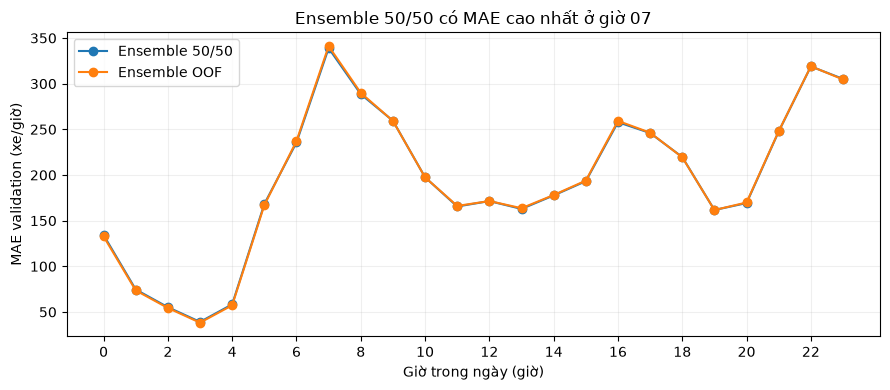

Đọc biểu đồ này như sau: so hai đường tại cùng một giờ. Giờ 07 có 252 mẫu; không kết luận nguyên nhân chỉ từ đường sai số.

,group,model,n,MAE,RMSE,bias
146,2017-05,Ensemble 50/50,523,169.890,269.514,22.330
147,2017-05,Ensemble OOF,523,169.451,270.461,21.842
150,2017-06,Ensemble 50/50,720,179.031,275.086,4.830
151,2017-06,Ensemble OOF,720,178.471,274.758,5.105
154,2017-07,Ensemble 50/50,726,180.841,292.067,-15.683
155,2017-07,Ensemble OOF,726,180.553,293.662,-15.038
158,2017-08,Ensemble 50/50,741,161.709,255.941,-32.392
159,2017-08,Ensemble OOF,741,161.812,256.316,-33.741
162,2017-09,Ensemble 50/50,709,186.949,298.357,-22.247
163,2017-09,Ensemble OOF,709,186.683,298.359,-23.245


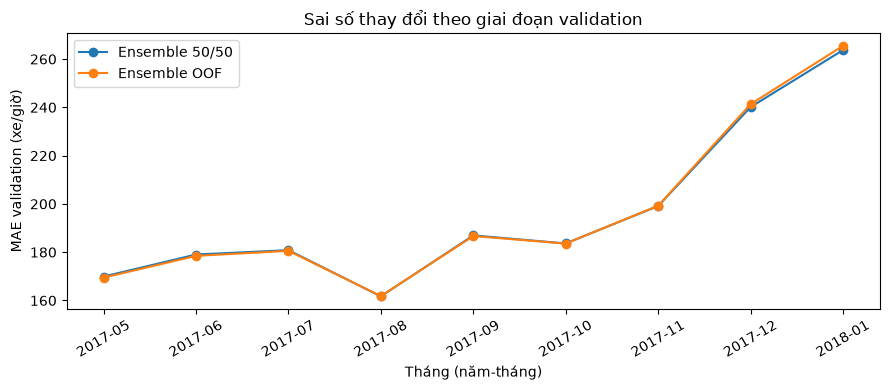

Đọc biểu đồ này như sau: tháng cao hơn có MAE lớn hơn trên những giờ được chấm. Mức lỗi giữa tháng còn phụ thuộc tập giờ và lưu lượng quan sát, không tự chứng minh mô hình bị drift.

In [10]:
hour_metrics = slice_metrics.loc[slice_metrics.condition.eq('hour')].copy()
hour_metrics['hour'] = hour_metrics.group.astype(int)
hour_50 = hour_metrics.loc[hour_metrics.model.eq('Ensemble 50/50')].sort_values('hour')
worst_hour = hour_50.loc[hour_50.MAE.idxmax()]
fig, ax = plt.subplots(figsize=(9,4))
for model_name in ['Ensemble 50/50','Ensemble OOF']:
    frame = hour_metrics.loc[hour_metrics.model.eq(model_name)].sort_values('hour')
    ax.plot(frame.hour,frame.MAE,marker='o',label=model_name)
ax.set(xlabel='Giờ trong ngày (giờ)',ylabel='MAE validation (xe/giờ)',
       title=f'Ensemble 50/50 có MAE cao nhất ở giờ {int(worst_hour.hour):02d}')
ax.set_xticks(range(0,24,2)); ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(figures_dir/'validation_C30_OOF_04_hour.png',dpi=150); plt.show()
display(Markdown(f'Đọc biểu đồ này như sau: so hai đường tại cùng một giờ. Giờ {int(worst_hour.hour):02d} có {int(worst_hour.n)} mẫu; không kết luận nguyên nhân chỉ từ đường sai số.'))
month_metrics = slice_metrics.loc[slice_metrics.condition.eq('calendar_month')]
display(month_metrics.loc[month_metrics.model.isin(['Ensemble 50/50','Ensemble OOF']),['group','model','n','MAE','RMSE','bias']].round(3))
fig, ax = plt.subplots(figsize=(9,4))
for model_name in ['Ensemble 50/50','Ensemble OOF']:
    frame = month_metrics.loc[month_metrics.model.eq(model_name)].sort_values('group')
    ax.plot(frame.group,frame.MAE,marker='o',label=model_name)
ax.set(xlabel='Tháng (năm-tháng)',ylabel='MAE validation (xe/giờ)',title='Sai số thay đổi theo giai đoạn validation')
ax.tick_params(axis='x',rotation=30); ax.legend(); fig.tight_layout()
fig.savefig(figures_dir/'validation_C30_OOF_05_month.png',dpi=150); plt.show()
display(Markdown('Đọc biểu đồ này như sau: tháng cao hơn có MAE lớn hơn trên những giờ được chấm. Mức lỗi giữa tháng còn phụ thuộc tập giờ và lưu lượng quan sát, không tự chứng minh mô hình bị drift.'))

## 11. Những giờ và ngày đóng góp nhiều lỗi

Xem các trường hợp lỗi lớn để đề xuất kiểm tra dữ liệu hoặc giả thuyết cho vòng sau. Đây là phân tích sau khi xem validation; không loại các giờ lỗi để làm đẹp điểm. Tỷ trọng lỗi là phần tổng sai số tuyệt đối do nhóm giờ đó đóng góp, không phải tỷ lệ dự đoán sai.

In [11]:
error_cases = analysis[['date_time','y_true','weather_main','is_holiday','is_rush_hour','after_gap_24h']].copy()
for name,column in [('RF','error_rf'),('XGBoost','error_xgb'),('Ensemble 50/50','error_50'),('Ensemble OOF','error_oof')]:
    error_cases[column] = prediction_sets[name]-analysis.y_true.to_numpy()
error_cases['abs_error_50'] = error_cases.error_50.abs()
error_cases['abs_error_oof'] = error_cases.error_oof.abs()
error_cases['day'] = error_cases.date_time.dt.normalize()
daily_errors = error_cases.groupby('day',as_index=False).agg(n=('date_time','size'),MAE_50_50=('abs_error_50','mean'),MAE_OOF=('abs_error_oof','mean'))
display(daily_errors.sort_values('MAE_50_50',ascending=False).head(10).round({'MAE_50_50':3,'MAE_OOF':3}))
largest_errors = error_cases.sort_values('abs_error_50',ascending=False)
display(largest_errors.head(20).round({'error_rf':3,'error_xgb':3,'error_50':3,'error_oof':3,'abs_error_50':3,'abs_error_oof':3}))
top_count = int(np.ceil(len(error_cases)*0.1))
top_error_share = float(largest_errors.head(top_count).abs_error_50.sum()/largest_errors.abs_error_50.sum())
display(pd.DataFrame([{'group':'10% giờ có sai số tuyệt đối 50/50 cao nhất','n':top_count,'absolute_error_share':top_error_share}]))
display(Markdown(f'{top_count:,} giờ lỗi lớn nhất đóng góp {top_error_share:.1%} tổng sai số tuyệt đối của 50/50. Cần kiểm tra dữ liệu và hoàn cảnh những giờ này; chưa thể coi đó là bằng chứng phải bỏ ngoại lệ.'))

,day,n,MAE_50_50,MAE_OOF
209,2017-12-05,21,695.413,695.555
246,2018-01-11,24,677.200,679.961
236,2018-01-01,24,635.772,663.616
55,2017-07-04,24,517.168,532.063
197,2017-11-23,24,493.974,512.739
117,2017-09-04,24,475.413,477.880
232,2017-12-28,24,458.978,466.580
229,2017-12-25,24,448.402,469.069
206,2017-12-02,24,429.818,433.391
184,2017-11-10,23,405.112,400.647


,date_time,y_true,weather_main,is_holiday,is_rush_hour,after_gap_24h,error_rf,error_xgb,error_50,error_oof,abs_error_50,abs_error_oof,day
4976,2017-12-05 07:00:00,2334,clear,0,1,0,3666.001,3634.101,3650.051,3653.241,3650.051,3653.241,2017-12-05
4977,2017-12-05 08:00:00,2160,snow,0,1,0,3358.083,3325.718,3341.900,3345.137,3341.900,3345.137,2017-12-05
2788,2017-09-04 06:00:00,1128,clear,1,1,0,2451.380,2376.971,2414.175,2421.616,2414.175,2421.616,2017-09-04
6004,2018-01-17 15:00:00,3271,clear,0,1,0,2300.167,2399.019,2349.593,2339.708,2349.593,2339.708,2018-01-17
2789,2017-09-04 07:00:00,1589,clouds,1,1,0,2439.622,2200.230,2319.926,2343.865,2319.926,2343.865,2017-09-04
5612,2018-01-01 07:00:00,677,clear,1,1,0,2737.887,1729.251,2233.569,2334.433,2233.569,2334.433,2018-01-01
4978,2017-12-05 09:00:00,2578,haze | snow,0,0,0,2189.399,2265.220,2227.310,2219.728,2227.310,2219.728,2017-12-05
4688,2017-11-23 07:00:00,991,clear,1,1,0,2863.303,1522.237,2192.770,2326.877,2192.770,2326.877,2017-11-23
1848,2017-07-26 23:00:00,3420,clear,0,0,0,-2096.231,-2059.334,-2077.782,-2081.472,2077.782,2081.472,2017-07-26
5611,2018-01-01 06:00:00,686,clear,1,1,0,2472.231,1539.911,2006.071,2099.303,2006.071,2099.303,2018-01-01


,group,n,absolute_error_share
0,10% giờ có sai số tuyệt đối 50/50 cao nhất,605,0.396824


605 giờ lỗi lớn nhất đóng góp 39.7% tổng sai số tuyệt đối của 50/50. Cần kiểm tra dữ liệu và hoàn cảnh những giờ này; chưa thể coi đó là bằng chứng phải bỏ ngoại lệ.

## 12. Tổng kết và xuất bằng chứng

Giữ tách biệt: trọng số được chọn trên OOF, kết quả kiểm tra trên validation, và quyết định có thay đối chứng hay không. Những điều kiện lỗi cao chỉ gợi ý giả thuyết; nếu thử mô hình hoặc đặc trưng mới phải lựa chọn trong train trước. Không tuyên bố MAE hiện tại là giới hạn của bài toán.

In [12]:
decision = ('Giữ ensemble 50/50 làm phương án hiện tại; trọng số OOF chưa cải thiện MAE validation.'
            if mae_gain <= 0 else 'Trọng số OOF giảm MAE validation trong lượt này; cần cân nhắc mức giảm, RMSE và giới hạn phân tích trước khi chốt.')
assessment = (
    f'OOF chọn RF {weight_rf:.0%}/XGBoost {weight_xgb:.0%} trên {len(oof):,} giờ, '
    f'giảm MAE trung bình fold {oof_gain:.4f} xe/giờ so với 50/50. '
    f'Trên cùng {len(validation):,} giờ validation, MAE 50/50 là {metric_index.loc["Ensemble 50/50","MAE"]:.4f}, '
    f'còn ensemble OOF là {metric_index.loc["Ensemble OOF","MAE"]:.4f} xe/giờ. '
    f'Chênh RMSE (50/50 trừ OOF) là {rmse_gain:.4f} xe/giờ. {decision}\n\n'
    f'Sai số RF và XGBoost có tương quan {residual_correlation:.3f}; '
    f'{same_direction.mean():.1%} giờ sai cùng chiều. Đổi trọng số không sửa được hướng sai ở những giờ đó. '
    f'Giờ {int(worst_hour.hour):02d} có MAE 50/50 cao nhất trong phân nhóm giờ; '
    f'10% giờ lỗi lớn nhất đóng góp {top_error_share:.1%} tổng sai số tuyệt đối. '
    'Các mẫu hình này mô tả validation, không chứng minh nguyên nhân.\n\n'
    f'{interval_comment} Validation đã được xem nhiều lần; bootstrap theo ngày chưa bao quát hết phụ thuộc qua nhiều ngày. '
    'Một seed, ba fold và lưới trọng số hữu hạn chưa chứng minh đã đạt giới hạn của bài toán. '
    'Phân tích chưa huấn luyện lại và chưa chấm test.'
)
display(Markdown(assessment))
tables = {'validation_metrics':metrics,'oof_weight_summary':weight_summary,'oof_fold_comparison':fold_comparison,
          'paired_bootstrap':bootstrap_results,'residual_direction':direction_table,
          'slice_metrics':slice_metrics,'slice_mae_comparison':slice_delta,'daily_errors':daily_errors,
          'largest_errors':largest_errors.head(50)}
for name,table in tables.items():
    table.to_csv(output_dir/f'{name}.csv',index=False)
(output_dir/'assessment.md').write_text(assessment+'\n',encoding='utf-8')
artifact_paths = [experiment_dir/name for name in ['selected_weights.json','oof_predictions.csv','fold_manifest.csv',
                  'weight_fold_scores.csv','validation_predictions.csv','validation_metrics.csv']]
analysis_record = {'seed':SEED,'n_oof':len(oof),'n_validation':len(validation),'weight_rf':weight_rf,'weight_xgb':weight_xgb,
    'inputs_sha256':{str(p.relative_to(project_root)):hashlib.sha256(p.read_bytes()).hexdigest() for p in artifact_paths},
    'source_config_sha256':hashlib.sha256(source_config_path.read_bytes()).hexdigest(),
    'n_bootstrap':2000,'bootstrap_unit':'calendar day','group_warning_n':MIN_GROUP_N,
    'gap_definition':'[first observed timestamp after missing hours, +24 calendar hours)',
    'weather_label_definition':'Rain/Snow/Drizzle/Thunderstorm/Squall/Fog/Mist',
    'validation_previously_seen':True,'model_refit':False,'test_evaluated':False,'decision':decision}
(output_dir/'analysis_record.json').write_text(json.dumps(analysis_record,ensure_ascii=False,indent=2),encoding='utf-8')
print('Đã lưu bảng, hình và tổng kết tại',output_dir.relative_to(project_root))

Đã lưu bảng, hình và tổng kết tại notebooks\validation\outputs\validation_C30_OOF


OOF chọn RF 60%/XGBoost 40% trên 16,875 giờ, giảm MAE trung bình fold 0.0249 xe/giờ so với 50/50. Trên cùng 6,050 giờ validation, MAE 50/50 là 193.8102, còn ensemble OOF là 193.9326 xe/giờ. Chênh RMSE (50/50 trừ OOF) là -1.4955 xe/giờ. Giữ ensemble 50/50 làm phương án hiện tại; trọng số OOF chưa cải thiện MAE validation.

Sai số RF và XGBoost có tương quan 0.949; 87.6% giờ sai cùng chiều. Đổi trọng số không sửa được hướng sai ở những giờ đó. Giờ 07 có MAE 50/50 cao nhất trong phân nhóm giờ; 10% giờ lỗi lớn nhất đóng góp 39.7% tổng sai số tuyệt đối. Các mẫu hình này mô tả validation, không chứng minh nguyên nhân.

Khoảng bootstrap chứa 0, chưa tách được chênh lệch khỏi mức bất định theo cách lấy mẫu này. Validation đã được xem nhiều lần; bootstrap theo ngày chưa bao quát hết phụ thuộc qua nhiều ngày. Một seed, ba fold và lưới trọng số hữu hạn chưa chứng minh đã đạt giới hạn của bài toán. Phân tích chưa huấn luyện lại và chưa chấm test.

## Quyết định cuối ngày 22/11/2026

Kết quả và kết luận phía trên thuộc phạm vi thí nghiệm lịch sử của notebook này. Nhóm đã chốt ensemble C30 ba mô hình: RF 25%, XGBoost 25%, ExtraTrees 50%. Xem [validation_final_C30.ipynb](validation_final_C30.ipynb) và [đặc tả đã khóa](outputs/final_C30/selected_model.json) cho bước fit cuối. Chưa refit trên train + validation và chưa chấm test.
